In [1]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import sys
import os

# to import karstnet from the src folder for developpement purpose
sys.path.append("../src")
import karstnet as kn

G = kn.io_func.networkx_from_yaml('../data/047_Seefeldhoele_000/047_Seefeldhoele_before_cleaning.yaml')

In [2]:

edges_add = [
    #CB: disconnected nodes
      ['Seefeldhoele.9.7', 'Seefeldhoele.197.1'],
      ['Seefeldhoele.178.3', 'Seefeldhoele.1.26'],
      ['Seefeldhoele.233.2', 'Seefeldhoele.8.15'],
      ['Seefeldhoele.78.1', 'Seefeldhoele.4.2'],
      ['Seefeldhoele.134.1', 'Seefeldhoele.1.1'],
      ['Seefeldhoele.95.1', 'Seefeldhoele.4.9'],
    #CB : connections based on map
      ['Seefeldhoele.190.6', 'Seefeldhoele.47.1'],
      ['Seefeldhoele.111.1', 'Seefeldhoele.107.1'],
      ['Seefeldhoele.253.3', 'Seefeldhoele.221.11'],
      ['Seefeldhoele.221.14', 'Seefeldhoele.256.2'],
      ['Seefeldhoele.256.6', 'Seefeldhoele.245.7'],
      ['Seefeldhoele.277.2', 'Seefeldhoele.273.2'],
      ['Seefeldhoele.166.3', 'Seefeldhoele.1.39'],
      ['Seefeldhoele.174.3', 'Seefeldhoele.171.2'],
      ['Seefeldhoele.172.1', 'Seefeldhoele.173.1'],
      ['Seefeldhoele.179.2', 'Seefeldhoele.1.24']
    ]


node_flag_ent = [
      ['Seefeldhoele.1.0', 'Entree1'],
      ['Seefeldhoele.2.0', 'Entree2']
    ]

In [3]:

flags = [x for l in list(nx.get_edge_attributes(G,'flags').values()) for x in l]
list_edges_dpl = [edge for edge, action in nx.get_edge_attributes(G,'flags').items() if (('dpl' in action) & ('de' not in action))]

In [6]:
flags = kn.clean.find_flags(G, attribute_name = 'flags')
list_edges_dpl = kn.clean.list_flagged_edges(G, 'flags', 'dpl')

In [7]:
flags

{'dpl'}

In [5]:
G.nodes('flags')

NodeDataView({464: None, 628: None, 262: None, 710: None, 210: None, 179: None, 281: None, 200: None, 511: None, 85: None, 318: None, 692: None, 22: None, 725: None, 751: None, 37: None, 43: None, 15: None, 446: None, 522: None, 138: None, 233: None, 624: None, 626: None, 649: None, 571: None, 527: None, 67: None, 731: None, 752: None, 180: None, 397: None, 588: None, 424: None, 661: None, 497: None, 569: None, 304: None, 328: None, 98: None, 462: None, 59: None, 157: None, 74: None, 646: None, 515: None, 370: None, 541: None, 520: ['fix'], 399: None, 168: None, 71: None, 531: None, 431: None, 670: None, 552: None, 447: None, 402: None, 231: None, 398: None, 453: None, 160: None, 430: None, 427: None, 728: None, 476: None, 423: None, 261: None, 3: None, 676: None, 738: None, 466: None, 717: None, 564: None, 736: None, 393: None, 663: None, 267: None, 40: None, 457: None, 664: None, 31: None, 273: None, 573: None, 158: None, 195: None, 409: None, 316: None, 625: None, 539: None, 23: Non

In [ ]:
G.__dict__

{'graph': {},
 '_node': {464: {'pos': [630232.15, 178499.69, 1776.28],
   'splays': [[630232.21, 178500.09, 1776.28],
    [630232.04, 178498.9, 1776.28],
    [630232.15, 178499.69, 1776.88],
    [630232.15, 178499.69, 1775.08],
    [630232.79, 178499.97, 1776.28],
    [630231.87, 178499.58, 1776.28],
    [630232.15, 178499.69, 1776.78],
    [630232.15, 178499.69, 1774.98],
    [630231.64, 178499.21, 1776.28],
    [630232.44, 178499.39, 1775.48]],
   'fulladdress': ['Seefeldhoele.1.10',
    'Seefeldhoele.90.0',
    'Seefeldhoele.150.15'],
   'idsql': [2, 1872, 2970],
   'csdim': [0.74, 0.74]},
  628: {'pos': [630234.99, 178497.86, 1774.93],
   'splays': [[630235.37, 178498.45, 1774.93],
    [630234.88, 178497.69, 1774.93],
    [630235.31, 178497.66, 1775.86],
    [630234.83, 178497.96, 1774.47]],
   'fulladdress': ['Seefeldhoele.1.11'],
   'idsql': [3],
   'csdim': [0.58, 1.42]},
  262: {'pos': [630229.0, 178500.15, 1777.19],
   'splays': [[630229.66, 178501.49, 1777.19],
    [630228.55

In [ ]:
disco_keys

NameError: name 'disco_keys' is not defined

There is  1 connected components in the original graph
There is  2 connected components in the graph without flagged edges


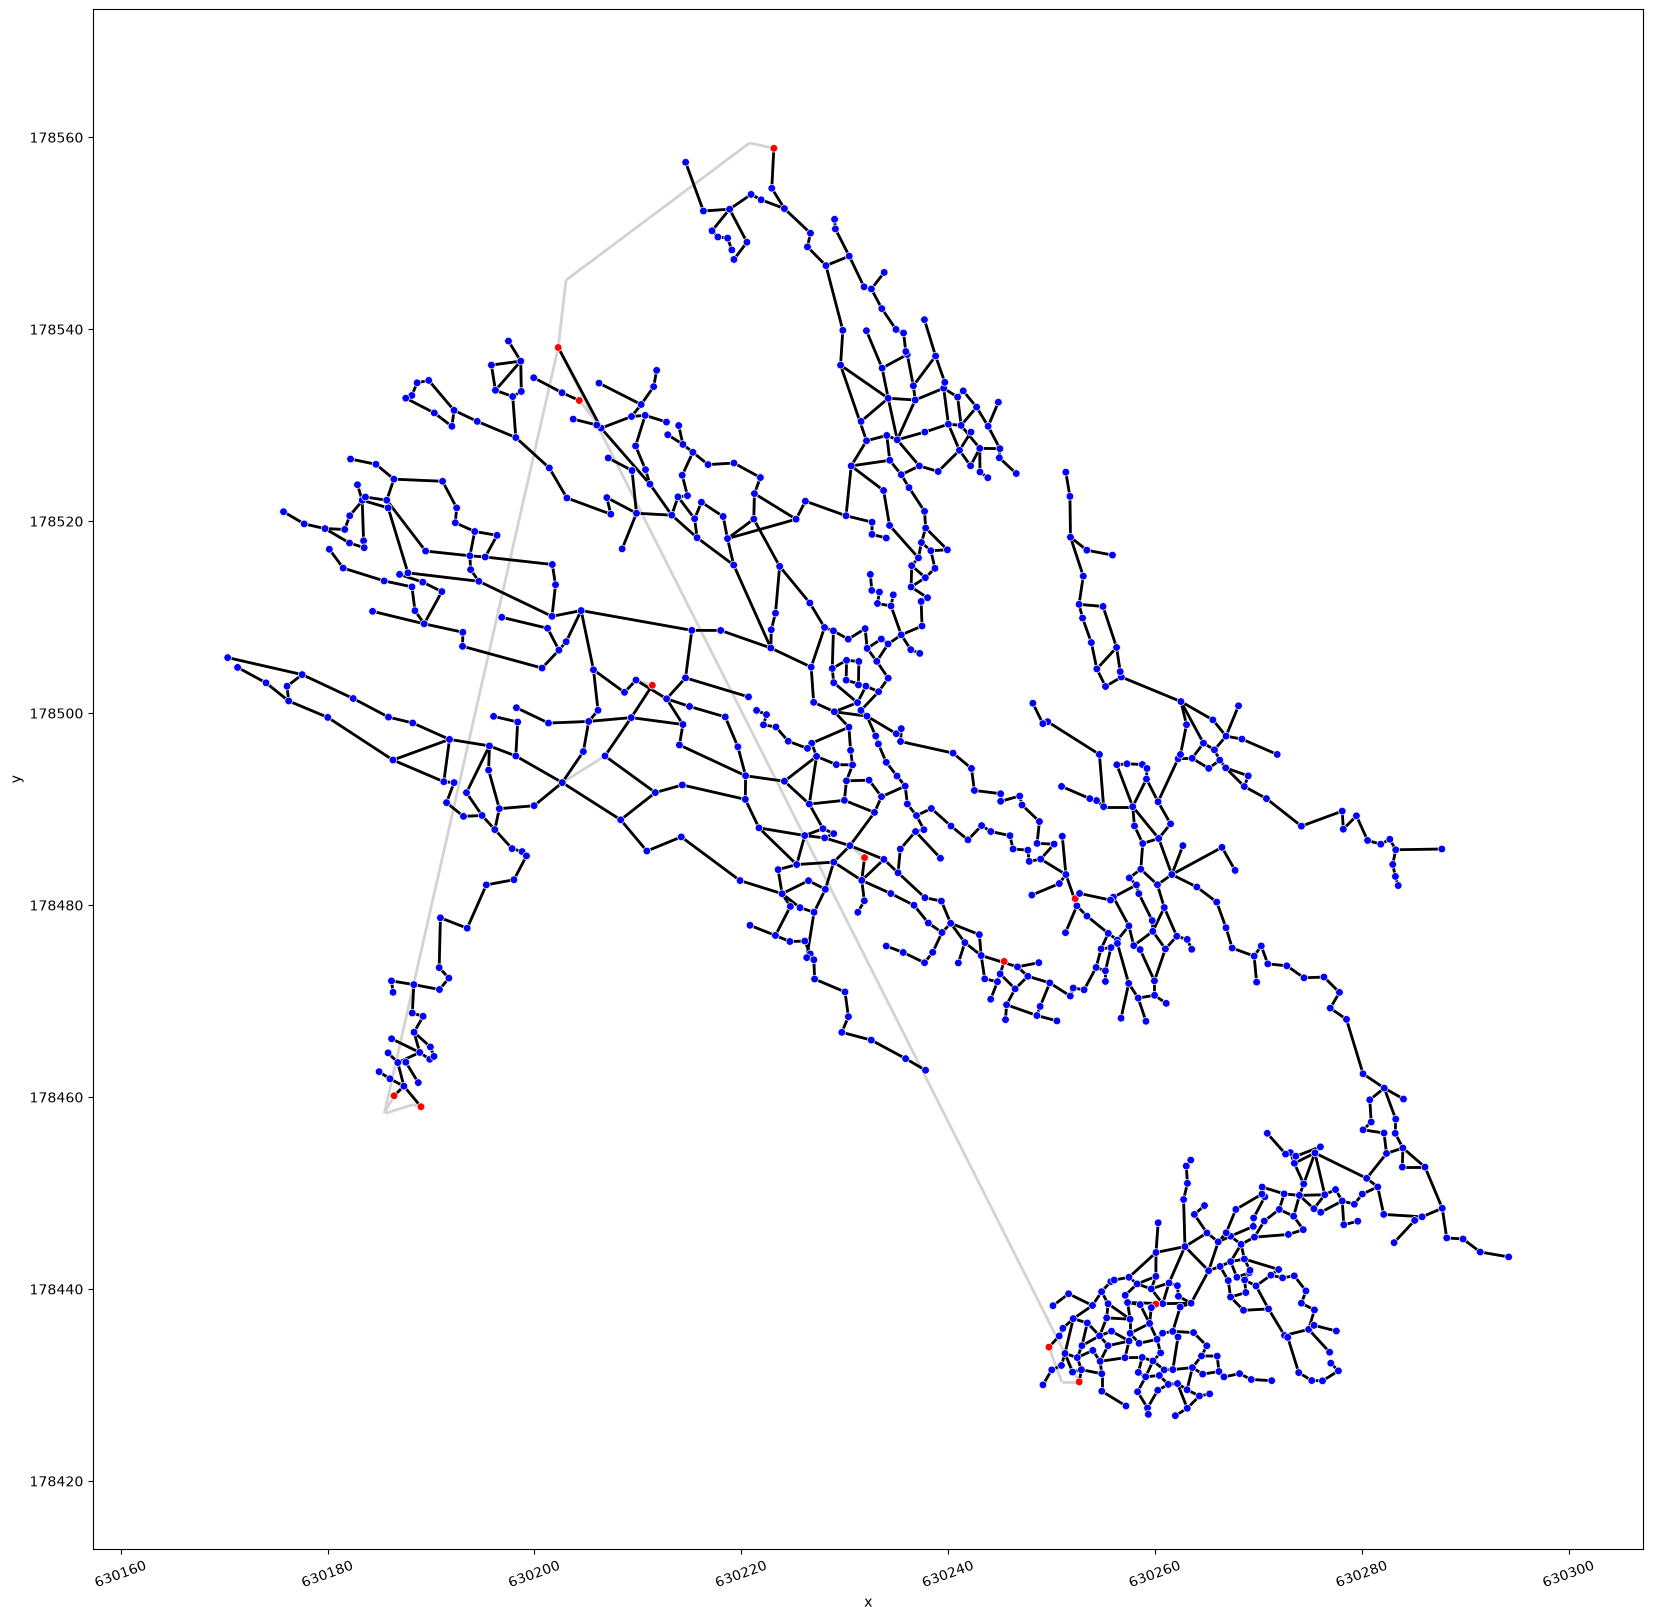

In [ ]:

#load graph graph data

# G = kn.io_func.networkx_from_yaml('../data/047_Seefeldhoele_000/047_Seefeldhoele_000.yaml')
H = G.copy()
kn.clean.remove_flagged_edges(H)

disco_keys = kn.clean.find_disconnected_node(G, H)

color = []
for key in H.nodes():
    if key in disco_keys:
        color.append('red')
    else:
        color.append('blue')      


# Plot 2D (no node / edge property) - projection onto Oxy (default)
options_1 = {
    'node_size'   : 0,          # node size
    'linewidths'  : 0.5,         # node border width       
    'edgecolors'  : 'white',       # node border color
    'node_color'  : 'white',       # node color
    'width'       : 2,           # edge width
    'edge_color'  : 'lightgray',      # edge color
    'with_labels' : False,       # show node labels ?
    # 'font_size'   : 10           # font size for labels
}

# Plot 2D (no node / edge property) - projection onto Oxy (default)
options_2 = {
    'node_size'   : 30,          # node size
    'linewidths'  : 0.5,         # node border width       
    'edgecolors'  : 'white',       # node border color
    'node_color'  : color,       # node color
    'width'       : 2,           # edge width
    'edge_color'  : 'black',      # edge color
    'with_labels' : False,       # show node labels ?
    # 'font_size'   : 10           # font size for labels
}

plt.figure(figsize=(20,20))

kn.view.plot_graph2d(
    G,
    plot_nodes=True, # default is True; set to False to hide nodes
    plot_edges=True, # default is True; set to False to hide edges
    show_ticks=True, 
    options_xaxis_ticks={'rotation':20},
    **options_1

)

kn.view.plot_graph2d(
    H,
    plot_nodes=True, # default is True; set to False to hide nodes
    plot_edges=True, # default is True; set to False to hide edges
    show_ticks=True, 
    options_xaxis_ticks={'rotation':20},
    **options_2


)

plt.show()

